# Praktikum 5
Klasifikasi Citra Siang dan Malam

Pada praktikum ini kita melakukan alur lengkap **pra pengolahan → ekstraksi fitur → klasifikasi** pada citra, dengan studi kasus membedakan foto **siang (`day`)** dan **malam (`night`)**.

**Dataset:** folder `images/` berisi `training/` (240 citra) dan `test/` (160 citra), masing-masing dengan subfolder `day` dan `night`.

Dua pendekatan dibandingkan:

1. **Threshold** pada rata-rata kecerahan — sederhana, tetapi ambangnya harus ditebak.
2. **SVM** dengan fitur rata-rata kecerahan — ambang belajar sendiri dari data.

Fitur yang dipakai adalah **rata-rata kanal V (Value)** dari ruang warna HSV, karena kanal V merepresentasikan kecerahan secara langsung.

### Langkah 0 - Import Library

In [1]:
from pathlib import Path
import matplotlib.image as mpimg
import matplotlib.pyplot as plt
import cv2
import random
import numpy as np
import pandas as pd

np.random.seed(42)

In [2]:
# Direktori gambar (relatif terhadap notebook)
train_dir = "images/training/"
test_dir = "images/test/"

### Langkah 1 - Load Data dan Visualisasikan
`load_dataset` menelusuri setiap subfolder, memakai nama folder sebagai label, lalu menyimpan pasangan `(gambar, label)`.

> **Perbaikan dari modul:** pada modul, `return img_list` berada **di dalam** `for dir in dirs`, sehingga fungsi hanya mengembalikan isi folder pertama (`day`). Di sini indentasinya dibetulkan agar `day` dan `night` sama-sama termuat, dan urutan folder dibuat `sorted` agar hasilnya deterministik.

In [3]:
def load_dataset(img_dir):
    p = Path(img_dir)
    dirs = sorted(p.glob('*'))

    img_list = []

    for dir in dirs:
        label = str(dir).split('/')[-1]
        for file in sorted(dir.glob('*.jpg')):
            img = mpimg.imread(file)

            if img is not None:
                img_list.append((img, label))

    return img_list

In [4]:
# Load data training
train_img = load_dataset(train_dir)

print('Jumlah citra latih:', len(train_img))
print('Contoh label:', train_img[0][1], train_img[-1][1])

Jumlah citra latih: 240
Contoh label: day night


Satu elemen list harus berupa tuple berisi **array gambar** dan **label**.

In [5]:
# Elemen pertama: pasangan (array gambar, label)
print(type(train_img[0]))
print(type(train_img[0][0]), train_img[0][0].dtype)
print('Label:', train_img[0][1])

<class 'tuple'>
<class 'numpy.ndarray'> uint8
Label: day


Ukuran citra pada dataset ini tidak seragam (bervariasi antara 640 sampai 1280 piksel), sehingga standardisasi ukuran wajib dilakukan sebelum ekstraksi fitur.

In [6]:
# Cek ukuran gambar secara acak
pick_random = np.random.randint(0, len(train_img))

print(f'Image {pick_random}')
print(train_img[pick_random][0].shape)

Image 102
(555, 800, 3)


In [7]:
# Fungsi untuk visualisasi
def random_img_viz(img_list):
    rand_num = np.random.randint(0, len(img_list))

    img = img_list[rand_num][0]
    label = img_list[rand_num][1]

    plt.imshow(img)
    plt.axis('off')
    print(f'Shape\t: {img.shape}')
    print(f'Label\t: {label}')

Shape	: (555, 800, 3)
Label	: night


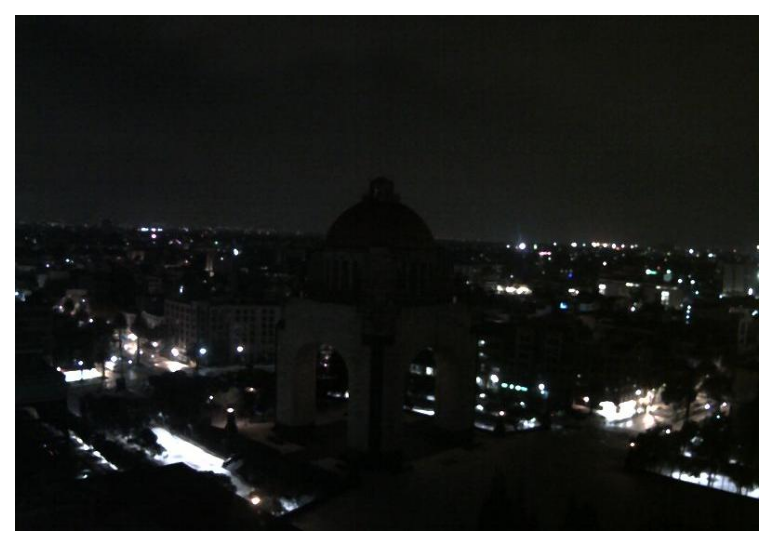

In [8]:
random_img_viz(train_img)

### Langkah 3 - Pra Pengolahan Data
Dua proses utama: **standardisasi ukuran** citra menjadi 1100 × 600 (lebar × tinggi) dan **encoding label** (`day` → 1, `night` → 0).

In [9]:
def standarized_input(image):
    # Resize ke lebar 1100, tinggi 600
    std_img = cv2.resize(image, (1100, 600))

    return std_img

In [10]:
def label_encoder(label):
    # day -> 1, night -> 0
    num_val = 0

    if label == 'day':
        num_val = 1

    return num_val

In [11]:
def preprocess(img_list):
    std_img_list = []

    for item in img_list:
        image = item[0]
        label = item[1]

        # Standardisasi ukuran gambar
        std_img = standarized_input(image)

        # Encoding label
        img_label = label_encoder(label)

        std_img_list.append((std_img, img_label))

    return std_img_list

> **Perbaikan dari modul:** sama seperti `load_dataset`, `return std_img_list` pada modul berada di dalam loop sehingga hanya satu citra yang diproses. Di sini dikembalikan setelah seluruh citra selesai diproses.

In [12]:
train_std_img_list = preprocess(train_img)

print('Jumlah citra terproses:', len(train_std_img_list))

# Gambar asli tidak dipakai lagi -> bebaskan memori
del train_img

Jumlah citra terproses: 240


In [13]:
# Cek ukuran gambar hasil pra pengolahan
pick_random = np.random.randint(0, len(train_std_img_list))

print(f'Image {pick_random}')
print(train_std_img_list[pick_random][0].shape)

Image 92
(600, 1100, 3)


Ukuran sekarang seragam: `(600, 1100, 3)`.

> **Perhatian:** `shape` citra selalu dilaporkan sebagai **(tinggi, lebar, kanal)** — `cv2.resize` memakai urutan **(lebar, tinggi)**. Tertukarnya urutan ini adalah sumber bug yang paling sering terjadi saat mengolah citra.

Shape	: (600, 1100, 3)
Label	: 1


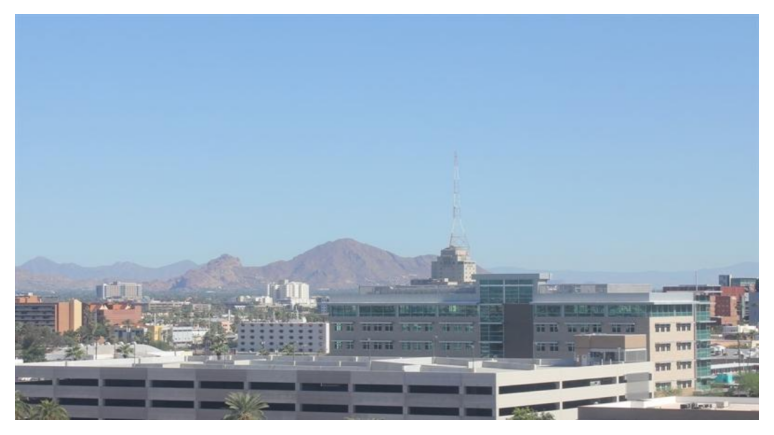

In [14]:
random_img_viz(train_std_img_list)

### Langkah 4 - Ekstraksi Fitur
Fitur adalah penciri yang membedakan satu data dari data lain. Di sini dipakai **rata-rata kecerahan** citra.

Sebelum itu, ruang warna diubah dari **RGB ke HSV** karena kecerahan lebih mudah diambil dari kanal **V (Value)** tanpa terpengaruh hue dan saturation.

In [15]:
# Fitur berbasis rata-rata kecerahan pada ruang warna HSV
def avg_brightness(image):
    # Konversi RGB -> HSV
    img_hsv = cv2.cvtColor(image, cv2.COLOR_RGB2HSV)

    # Jumlahkan kanal V (indeks 2), lalu bagi luas citra
    sum_brightness = np.sum(img_hsv[:, :, 2])
    area = image.shape[0] * image.shape[1]
    avg = sum_brightness / area

    return avg

Image 106
Label: 1
Avg Brightness: 135.2176


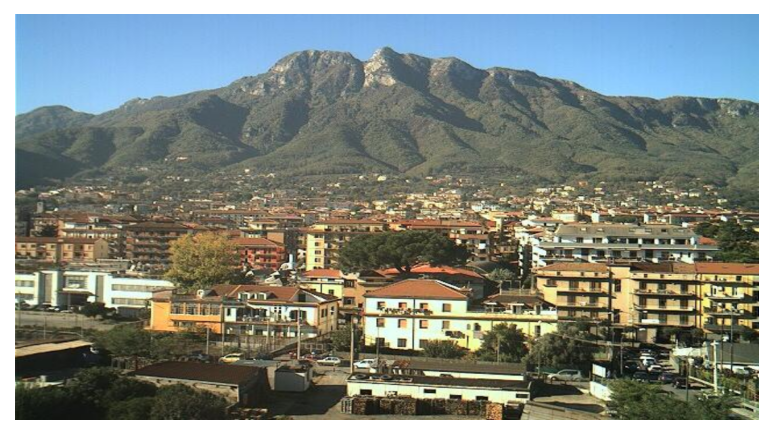

In [16]:
# Cek fitur pada citra acak (gunakan citra yang SUDAH dipra-proses)
rand_img = np.random.randint(0, len(train_std_img_list))

feature_img = train_std_img_list[rand_img][0]
avg_img = avg_brightness(feature_img)

print(f'Image {rand_img}')
print(f'Label: {train_std_img_list[rand_img][1]}')
print(f'Avg Brightness: {avg_img:.4f}')

plt.imshow(feature_img)
plt.axis('off')
plt.show()

### Langkah 5 - Klasifikasi dengan Metode Threshold
Klasifikasi paling sederhana: bila rata-rata kecerahan melebihi ambang tertentu, citra dianggap **siang**.

In [17]:
def predict_label(img, threshold):
    avg = avg_brightness(img)
    pred = 0

    # Prediksi berdasarkan ambang yang ditentukan pengguna
    if avg > threshold:
        pred = 1

    return pred

Image 71
Actual label: 1
Predicted label: 0


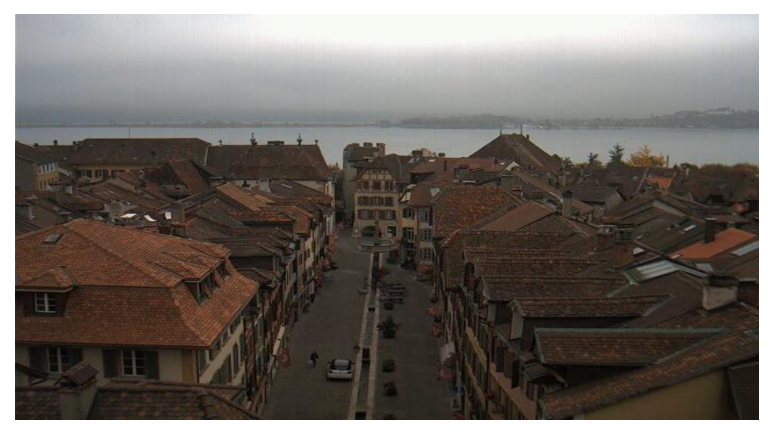

In [18]:
rand_img = np.random.randint(0, len(train_std_img_list))

pred = predict_label(train_std_img_list[rand_img][0], threshold=120)

print(f'Image {rand_img}')
print(f'Actual label: {train_std_img_list[rand_img][1]}')
print(f'Predicted label: {pred}')

plt.imshow(train_std_img_list[rand_img][0])
plt.axis('off')
plt.show()

### Langkah 6 - Evaluasi Manual
Evaluasi dilakukan dengan menghitung proporsi prediksi yang benar — bentuk paling sederhana dari akurasi.

> **Perbaikan dari modul:** `total_img = len(img_list)` pada modul berada di dalam loop (dihitung berulang). Di sini dihitung sekali setelah loop, dan fungsi mengembalikan nilai akurasi agar bisa dipakai untuk menyapu beberapa nilai threshold.

In [19]:
def evaluate(img_list, threshold):
    miss_labels = []

    for file in img_list:
        # Ground truth
        img = file[0]
        label = file[1]

        # Prediksi
        pred_label = predict_label(img, threshold)

        # Bandingkan
        if pred_label != label:
            miss_labels.append((img, pred_label, label))

    total_img = len(img_list)
    corr_pred = total_img - len(miss_labels)
    accuracy = corr_pred / total_img

    print(f'Accuracy: {accuracy:.4f} (salah {len(miss_labels)} dari {total_img})')
    return accuracy

In [20]:
# Evaluasi pada data latih
acc_train_thr = evaluate(train_std_img_list, threshold=120)

Accuracy: 0.8417 (salah 38 dari 240)


Data uji harus diperlakukan **persis sama** dengan data latih: pra pengolahan lalu ekstraksi fitur (tidak boleh ada informasi dari data latih yang "bocor" maupun sebaliknya).

In [21]:
# Load, pra-proses, lalu evaluasi data uji
test_img = load_dataset(test_dir)
test_std_img_list = preprocess(test_img)
del test_img

acc_test_thr = evaluate(test_std_img_list, threshold=120)

Accuracy: 0.8688 (salah 21 dari 160)


In [22]:
# Sapu nilai threshold untuk melihat sensitivitasnya
baris = []
for t in range(60, 220, 20):
    baris.append({
        'threshold': t,
        'akurasi_train': evaluate(train_std_img_list, t),
        'akurasi_test': evaluate(test_std_img_list, t),
    })

rekap_thr = pd.DataFrame(baris)
rekap_thr.round(4)

Accuracy: 0.7083 (salah 70 dari 240)


Accuracy: 0.7750 (salah 36 dari 160)


Accuracy: 0.7333 (salah 64 dari 240)


Accuracy: 0.7875 (salah 34 dari 160)


Accuracy: 0.9042 (salah 23 dari 240)


Accuracy: 0.9250 (salah 12 dari 160)


... (7 outputs left out)

Accuracy: 0.5625 (salah 70 dari 160)


Accuracy: 0.5042 (salah 119 dari 240)


Accuracy: 0.5062 (salah 79 dari 160)


,threshold,akurasi_train,akurasi_test
0,60,0.7083,0.7750
1,80,0.7333,0.7875
2,100,0.9042,0.9250
3,120,0.8417,0.8688
4,140,0.6875,0.7438
5,160,0.5875,0.5688
6,180,0.5583,0.5625
7,200,0.5042,0.5062


Terlihat akurasi **sangat sensitif** terhadap pilihan threshold: `threshold=100` memberi **0,904 (latih) / 0,925 (uji)**, sedangkan `threshold=160` turun drastis menjadi **0,588 / 0,569**. Artinya ambangnya harus ditentukan sendiri, dan salah memilih ambang berakibat besar pada performa — inilah kelemahan pendekatan manual.

**Selanjutnya: klasifikasi dengan SVM.** Seluruh langkah serupa, hanya Langkah 4 ke atas yang berubah — fitur ditabulasi, lalu model SVM belajar batas keputusan dari data.

### Langkah 4 Alternatif - Membuat Feature Vectors
Fitur semua citra ditabulasi menjadi tabel dengan kolom `AVG_BRIGHT` dan `LABELS`.

In [23]:
def extract_avg_bright_feature(img_list):
    avg_list = []
    labels = []

    for img in img_list:
        img_avg = avg_brightness(img[0])
        img_label = img[1]

        avg_list.append(img_avg)
        labels.append(img_label)

    # Susun sebagai kolom
    data = np.column_stack((avg_list, labels))
    df = pd.DataFrame(data, columns=['AVG_BRIGHT', 'LABELS'])

    return df

In [24]:
train_avg_img = extract_avg_bright_feature(train_std_img_list)
print(f'Shape: {train_avg_img.shape}')
train_avg_img.head()

Shape: (240, 2)


,AVG_BRIGHT,LABELS
0,175.092992,1.0
1,192.907867,1.0
2,132.133823,1.0
3,199.749191,1.0
4,109.947203,1.0


In [25]:
test_avg_img = extract_avg_bright_feature(test_std_img_list)
print(f'Shape: {test_avg_img.shape}')
test_avg_img.head()

Shape: (160, 2)


,AVG_BRIGHT,LABELS
0,194.228062,1.0
1,157.826662,1.0
2,201.607444,1.0
3,191.237441,1.0
4,188.119652,1.0


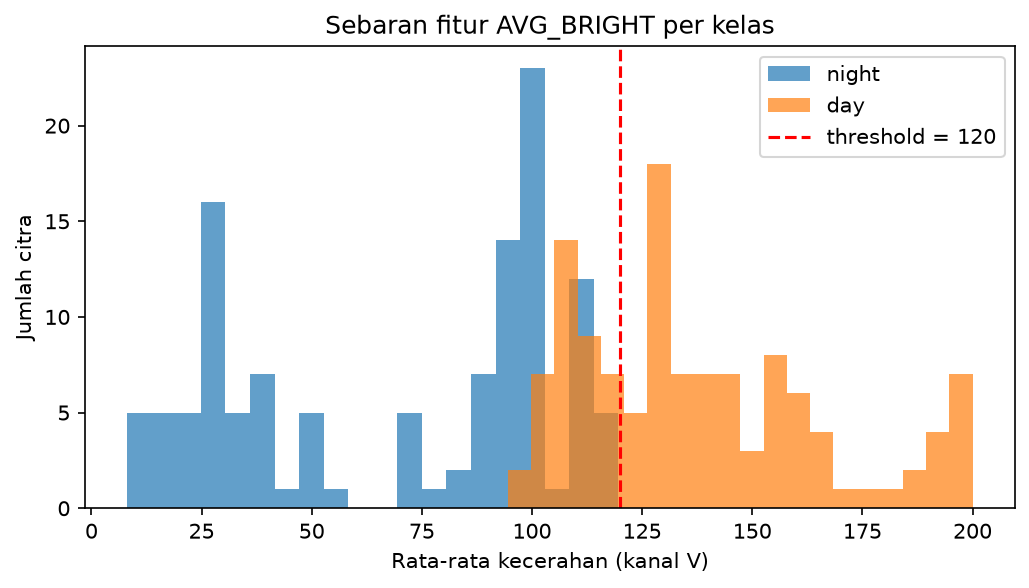

In [26]:
# Sebaran fitur per kelas
train_avg_img['LABELS'] = train_avg_img['LABELS'].astype(int)

plt.figure(figsize=(8, 4))
plt.hist(train_avg_img.loc[train_avg_img['LABELS'] == 0, 'AVG_BRIGHT'],
         bins=20, alpha=0.7, label='night')
plt.hist(train_avg_img.loc[train_avg_img['LABELS'] == 1, 'AVG_BRIGHT'],
         bins=20, alpha=0.7, label='day')
plt.axvline(120, color='red', linestyle='--', label='threshold = 120')
plt.xlabel('Rata-rata kecerahan (kanal V)')
plt.ylabel('Jumlah citra')
plt.title('Sebaran fitur AVG_BRIGHT per kelas')
plt.legend()
plt.show()

Grafik di atas menjelaskan mengapa SVM bisa bekerja dengan **satu fitur saja**: kedua kelas terpisah cukup rapi pada sumbu kecerahan. SVM akan mencari batas pemisahnya secara otomatis, tanpa kita tentukan nilainya.

### Langkah 5 - Buat Model SVM

In [27]:
from sklearn.svm import SVC

# Pisahkan fitur dan label
X_train = train_avg_img['AVG_BRIGHT'].to_numpy().reshape(-1, 1)
y_train = train_avg_img['LABELS'].to_numpy().astype(int)

X_test = test_avg_img['AVG_BRIGHT'].to_numpy().reshape(-1, 1)
y_test = test_avg_img['LABELS'].to_numpy().astype(int)

model = SVC()
model.fit(X_train, y_train)

print('Kernel:', model.kernel, '| C:', model.C, '| gamma:', model.gamma)

Kernel: rbf | C: 1.0 | gamma: scale


> **Penyesuaian:** `column_stack` pada Langkah 4 Alternatif menghasilkan kolom bertipe float, sehingga label terbaca `0.0`/`1.0`. Di sini label dikonversi eksplisit ke `int` agar tipe target benar-benar kategorikal.

### Langkah 6 - Evaluasi

In [28]:
from sklearn.metrics import accuracy_score

# Prediksi dan akurasi data latih
y_train_pred = model.predict(X_train)
acc_train = accuracy_score(y_train, y_train_pred)

# Prediksi dan akurasi data uji
y_test_pred = model.predict(X_test)
acc_test = accuracy_score(y_test, y_test_pred)

print(f'Accuracy on train: {acc_train}')
print(f'Accuracy on test: {acc_test}')

Accuracy on train: 0.8625
Accuracy on test: 0.9


              precision    recall  f1-score   support

       night       0.88      0.93      0.90        80
         day       0.92      0.88      0.90        80

    accuracy                           0.90       160
   macro avg       0.90      0.90      0.90       160
weighted avg       0.90      0.90      0.90       160



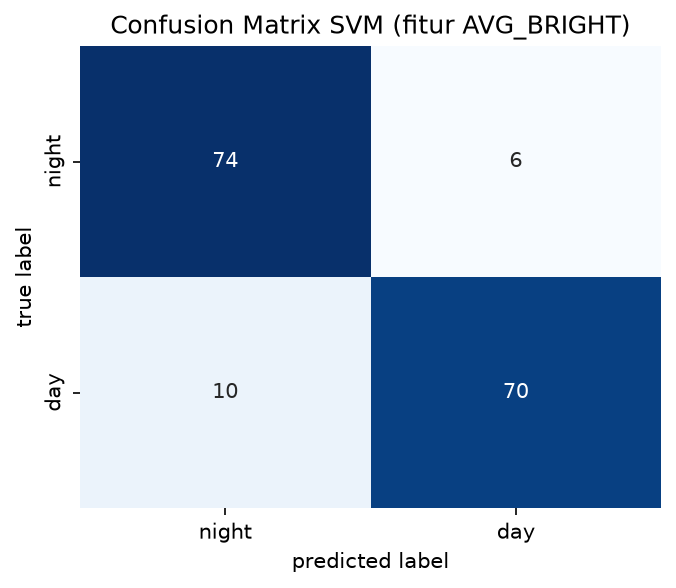

In [29]:
from sklearn.metrics import classification_report, confusion_matrix
import seaborn as sns

print(classification_report(y_test, y_test_pred, target_names=['night', 'day']))

mat = confusion_matrix(y_test, y_test_pred)
plt.figure(figsize=(5, 4))
sns.heatmap(mat, annot=True, fmt='d', cbar=False, cmap='Blues',
            xticklabels=['night', 'day'], yticklabels=['night', 'day'])
plt.xlabel('predicted label')
plt.ylabel('true label')
plt.title('Confusion Matrix SVM (fitur AVG_BRIGHT)')
plt.show()

In [30]:
# Batas keputusan yang dipelajari SVM (dalam satuan kecerahan)
print(f'Rata-rata kecerahan kelas night: {X_train[y_train == 0].mean():.2f}')
print(f'Rata-rata kecerahan kelas day  : {X_train[y_train == 1].mean():.2f}')
print(f'Batas keputusan (threshold manual) : 120')

Rata-rata kecerahan kelas night: 69.19
Rata-rata kecerahan kelas day  : 137.36
Batas keputusan (threshold manual) : 120


### Kesimpulan

* Alur klasifikasi citra berjalan lengkap: **load → standardisasi ukuran → ekstraksi fitur (rata-rata kanal V) → klasifikasi → evaluasi**.
* Metode **threshold** memberi akurasi **0,8417 (latih)** dan **0,8688 (uji)** pada `threshold=120`, dan bisa mencapai **0,904 / 0,925** bila ambangnya digeser ke 100. Masalahnya, ambang itu harus dicari manual dan akurasi anjlok ke **0,57** pada `threshold=160`.
* **SVM** dengan fitur yang sama memberi akurasi **0,8625 (latih)** dan **0,9000 (uji)** dengan pengaturan default. Batas keputusannya dipelajari dari data, sehingga tidak perlu menebak ambang.
* Investigasi penting: modul menaruh `return` di dalam loop pada `load_dataset` dan `preprocess`. Tanpa perbaikan, kedua fungsi hanya memproses **satu** citra dan akurasi menjadi tidak bermakna.
* Keterbatasan: satu fitur kecerahan global gagal pada kasus ekstrem (mis. langit sore yang terangnya mirip siang, atau kota malam yang penuh lampu). Pada Tugas Praktikum, fitur diganti **histogram** agar informasi sebaran kecerahan ikut terpakai.